In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

from scipy.sparse.linalg import svds

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from matplotlib import pyplot as plt

In [3]:
%matplotlib inline

In [4]:
sub = tifffile.imread("./dendrites_rect_filtered.tif")

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
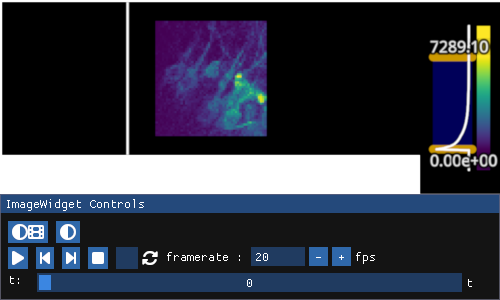

In [5]:
iw_sub = fpl.ImageWidget(sub, cmap="viridis")
iw_sub.show()

In [77]:
# strong cell on left
period_1 = (2150, 2500)

RFBOutputContext()

JupyterWgpuCanvas()
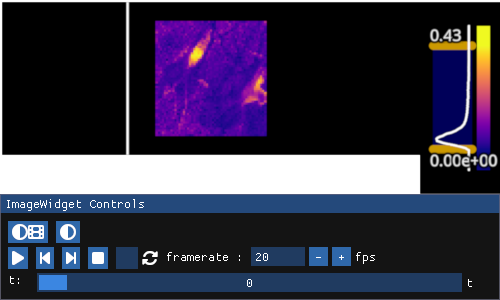

In [59]:
labels = np.load("./dendrites_15_spatial.npy").swapaxes(0, 1).T
fpl.ImageWidget(labels).show()

In [60]:
cell_ix = 13

RFBOutputContext()

JupyterWgpuCanvas()
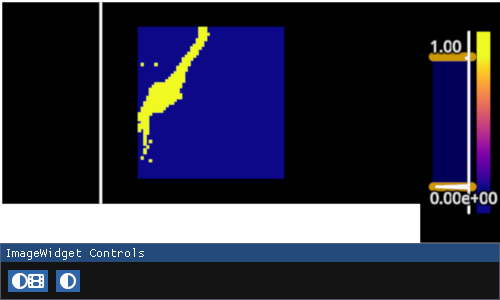

In [61]:
A = labels[cell_ix]
A[A < 0.099] = 0
A = A.astype(bool)

fpl.ImageWidget(A).show()

In [62]:
A_ixs = np.where(A)
A_shape = A.shape

In [63]:
def recover(pixels: np.ndarray, shape: tuple[int, int], indices: np.ndarray) -> np.ndarray:
    r = np.zeros(shape)
    r[indices] = pixels
    return r

In [78]:
Ya = sub[slice(*period_1), *A_ixs].T

In [79]:
Ya.shape

(237, 350)

In [80]:
from ipywidgets import IntSlider, VBox, HBox

In [135]:
iw_rec = fpl.ImageWidget(recover(Ya[:, 0], A.shape, A_ixs), cmap="viridis", figure_kwargs={"size": (520, 600)})
iw_rec.show()

g = iw_rec.managed_graphics[0]

g.vmin, g.vmax = Ya.min(), Ya.max()

fig_heatmap = fpl.Figure(size=(900, 600))
fig_heatmap[0, 0].add_image(Ya, cmap="viridis")

time_selector = fig_heatmap[0, 0].graphics[0].add_linear_selector()

@time_selector.add_event_handler("selection")
def update_time(ev):
    ix = ev.get_selected_index()
    iw_rec.managed_graphics[0].data = recover(Ya[:, ix], A.shape, A_ixs)

HBox([iw_rec.show(), fig_heatmap.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [82]:
Ya.nbytes / 1024 / 1024

0.31642913818359375

In [83]:
from tqdm import tqdm
from scipy.linalg import hankel

In [84]:
w2 = 100 * 2
w = int(w2 / 2)
t = 150

Ys = list()
Ps = list()
Fs = list()

n_pixels = Ya.shape[0]

for i in tqdm(range(n_pixels)):
    y = hankel(Ya[i, t: t + w2], Ya[i, t:t + w2])
    p = np.flipud(y[:w])
    f = y[w:]

    Ps.append(p)
    Fs.append(f)

P_F_shape = (w * n_pixels, w2)

100%|████████████████████████████████████████████████████████████████████| 237/237 [00:00<00:00, 18054.93it/s]


In [85]:
y.shape, p.shape, f.shape

((200, 200), (100, 200), (100, 200))

In [86]:
P_F_shape

(23700, 200)

In [87]:
P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

In [88]:
for i in tqdm(range(n_pixels)):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

100%|████████████████████████████████████████████████████████████████████| 237/237 [00:00<00:00, 10584.12it/s]


In [89]:
H = (F @ P.T) / P.shape[1]

In [90]:
from itertools import product

In [91]:
print("Computing Hp")
Hp = np.zeros((w ** 2, n_pixels ** 2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, w * n_pixels, n_pixels)] * 2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

del H

Computing Hp


In [92]:
Hp.shape

(10000, 56169)

In [93]:
u, s, v = svds(Hp, k=6)

In [94]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

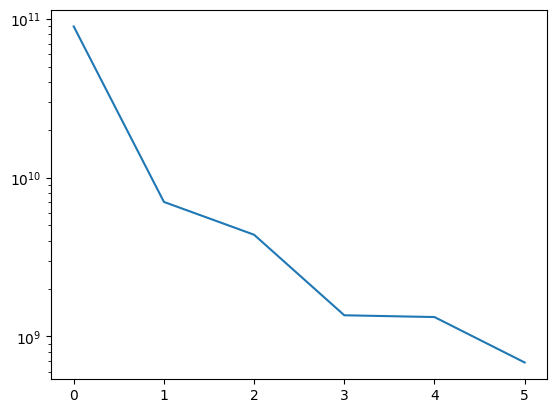

In [95]:
plt.plot(s)
plt.semilogy()
plt.show()

In [96]:
Ya.shape

(237, 350)

In [113]:
PAIR_INDEX = 1

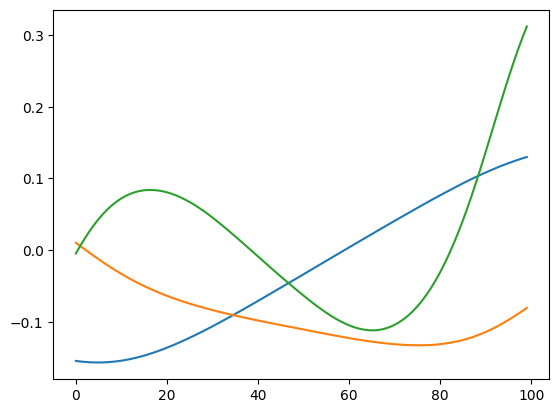

In [114]:
Ur = u[:, PAIR_INDEX].reshape(w, w)

u_t, s_t, v_t = np.linalg.svd(Ur)

for i in range(3):
    plt.plot(v_t[i])

In [115]:
# time x time
B = v[PAIR_INDEX].reshape(Ya.shape[0], Ya.shape[0])

In [116]:
B.shape

(237, 237)

In [117]:
img0 = recover(B[0], A.shape, A_ixs)

### I think that each B_i cov matrix here represents: For this given temporal mode how do the pixels co-vary

# USE CURSOR TOOL WITH STICK ON COV MATRIX, DISPLAY ROW AND COLUMN IMAGES

# Here it makes sense for V to be negative, reflect the differences between the cell body and dendrites

RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
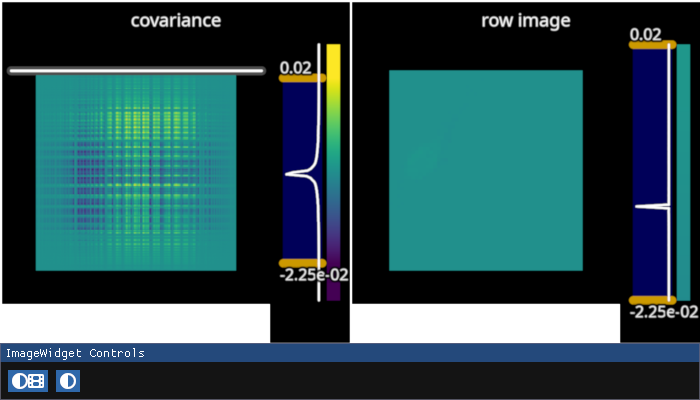

In [118]:
figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[B, img0],
    cmap="viridis",  # diverging colormap
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

g = iw.managed_graphics[1]
g.vmin, g.vmax = B.min(), B.max()

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = recover(B[ix], A.shape, A_ixs)

    iw.managed_graphics[1].data = img

iw.show()

In [119]:
iw.cmap = "bwr"

In [120]:
u_s, s_s, v_s = np.linalg.svd(B)

[]

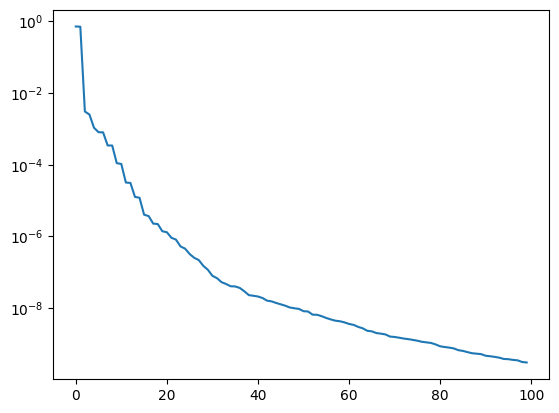

In [121]:
plt.plot(s_s[:100])
plt.semilogy()

In [122]:
u_s_images = np.dstack([recover(u_s[i], A.shape, A_ixs).T for i in range(u_s.shape[1])]).T
v_s_images = np.dstack([recover(v_s[i], A.shape, A_ixs).T for i in range(v_s.shape[1])]).T

## Images of first 3 future and past space

In [123]:
iw_u_s = fpl.ImageWidget([u_s_images[i] for i in range(3)], cmap="bwr", figure_shape=(1, 3))


iw_v_s = fpl.ImageWidget([v_s_images[i] for i in range(3)], cmap="bwr", figure_shape=(1, 3))
VBox([iw_u_s.show(), iw_v_s.show()])

RFBOutputContext()

RFBOutputContext()

In [127]:
for iw in iw_u_s, iw_v_s:
    iw.cmap = "viridis"

In [128]:
np.linalg.norm((B - B.T) / np.linalg.norm(B, ord="fro"), ord="fro")

np.float64(1.9998746174994686)

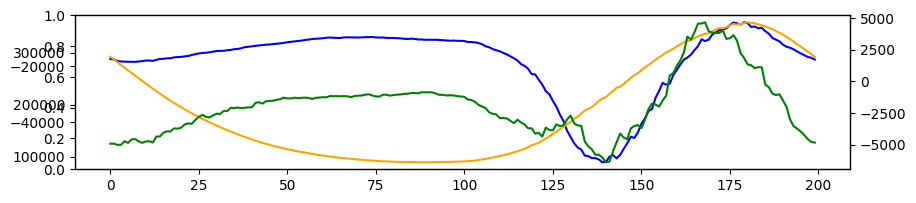

In [129]:
filtered = list()

for i in range(3):
    filtered.append(np.kron(v_s[i], v_t[i]) @ P)

fig = plt.figure(figsize=(10, 2))

colors = ["blue", "orange", "green"]
for i in range(3):
    plt.twinx()
    plt.plot(filtered[i], label=i, c=colors[i])

plt.show()

In [130]:
filtered_movies = list()

for i in range(3):
    mov = np.outer(v_s[i] * s_s[i], filtered[i])
    mov = np.dstack([recover(mov[:, t], A.shape, A_ixs).T for t in range(mov.shape[1])]).T
    filtered_movies.append(mov)

RFBOutputContext()

JupyterWgpuCanvas()
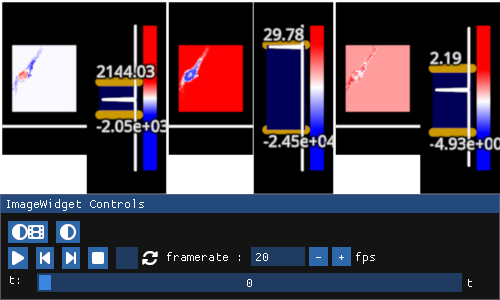

In [131]:
iw_filtered = fpl.ImageWidget(filtered_movies, cmap="bwr", figure_shape=(1, 3))
iw_filtered.show()